# GRU Experiment A — class weights with fixed TRAIN / TEST inputs
Compare five positive weights using five-fold grouped CV on TRAIN only (25 fits). Select by mean fold trapezoidal PR AUC, then ROC AUC, then smaller alpha. Refit the winner on all TRAIN (one additional fit). Optional final evaluation uses TEST only.

Architecture, optimiser, seed and 20 epochs are unchanged. No early stopping: every fold uses the final epoch. The GRU consumes 45 summaries as 3 × 15, seven-base sequence encoding, and log valid-read count. The seven-base encoding deliberately preserves the original experiment; it differs from the cleaner’s central-5mer allowlist, but uses the exported `sequence` column. Labels, modification fractions, IDs and split metadata are never predictors.

**Start:** edit `PROJECT_ROOT` and `CLEAN_RUN_DIR` in Section 2 to the timestamped folder printed by your new cleaner. Alternatively edit the six CSV paths. Run all cells. No raw JSON is needed.

**Split policy:** matches the supplied running training notebook. Datasets0/1 use connected transcript/gene/supplied-group components. Dataset2 uses confirmed shared-position groups, allowing repeated mixture IDs across splits while keeping each position group together. Exact-site and effective-group overlaps still stop the run. Dataset2 sequence agreement and group-to-position correspondence are checked. No rows or split assignments are changed. This estimates held-out positions within the mixture construction, not unseen dataset2 transcripts.

**Keep TEST untouched while improving architecture:** set `EVALUATE_TEST=False` during exploratory rounds. Enable it after the full modelling procedure is fixed. Never select weights, architecture, epochs or thresholds from TEST scores.

No real training results are embedded. Save this notebook after running to retain its charts.


## 1. Environment

In [1]:
# Uncomment once if packages are missing; restart the kernel afterwards.
# %pip install "numpy>=1.24,<3" "pandas>=2,<3" "scikit-learn>=1.3,<2" "matplotlib>=3.7,<4" "torch>=2.2,<3" "joblib>=1.3,<2" ipykernel
from pathlib import Path
from datetime import datetime, timezone
import gc, gzip, hashlib, importlib.metadata, json, random, re, shutil, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import StratifiedGroupKFold, ParameterSampler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
    roc_curve, auc, precision_score, recall_score, f1_score, accuracy_score)
from IPython.display import display
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)
import time

## 2. Paths and fixed experiment settings
Set the timestamp folder containing dataset0, dataset1 and dataset2 subfolders. Output runs are timestamped. `RUN_TRAINING=False` plus `EXISTING_RUN_DIR` reloads saved plots and metrics without retraining. `EVALUATE_TEST` can evaluate the saved selected model in this mode too. Keep outputs excluded from Git.


In [2]:
PROJECT_ROOT = Path('/home/ubuntu/project')
CLEAN_RUN_DIR = PROJECT_ROOT / 'outputs' / 'data_cleaning' / '20261014T062257_386425Z'
DATASETS = [
    dict(
        dataset_id=name,
        train_file=CLEAN_RUN_DIR / name / f'{name}_clean_train.csv.gz',
        test_file=CLEAN_RUN_DIR / name / f'{name}_clean_test.csv.gz',
        manifest_file=CLEAN_RUN_DIR / name / 'run_manifest.json',
    )
    for name in ['dataset0', 'dataset1', 'dataset2']
]
OUTPUT_ROOT = PROJECT_ROOT / 'outputs' / 'gru_class_weight_train_test'
# Enabled per your confirmation that dataset2 uses shared-position mixture groups.
# Set False if that interpretation has not been established for your data.
DATASET2_POSITION_GROUPS_CONFIRMED = True
SEED = 42
N_FOLDS = 5
THRESHOLD = 0.5  # Only for precision/recall/F1; ROC/PR AUC use continuous scores.
PREDICT_BATCH_SIZE = 1024
RUN_TRAINING = True
EXISTING_RUN_DIR = None  # e.g. Path('/home/ubuntu/project/outputs/gru_class_weight/2026...')
REFIT_SELECTED = True
EVALUATE_TEST = False # Enable only when the full modelling procedure is final.
ALPHAS = [0.0, 0.25, 0.5, 0.75, 1.0]
BASE_CONFIG = dict(hidden_size=32, dropout=0.2, lr=1e-3, weight_decay=1e-4,
                   batch_size=256, epochs=20, class_weighting=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def resolve_path(value):
    p = Path(value).expanduser()
    return (p if p.is_absolute() else PROJECT_ROOT / p).resolve()
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
seed_everything(SEED)
print('Device:', DEVICE, '| PyTorch:', torch.__version__)
print('CV fits:', N_FOLDS * len(ALPHAS), '| optional final refit:', REFIT_SELECTED)


Device: cpu | PyTorch: 2.14.1+cu130
CV fits: 25 | optional final refit: True


## 3. Load and validate the unchanged cleaned features
Scaling is still fitted only within training folds. Results-only mode skips input loading.

In [3]:
LOCATIONS = ['minus1', 'center', 'plus1']
MEASURES = ['dwell', 'signal_sd', 'signal_mean']
STATS = ['mean', 'std', 'median', 'q25', 'q75']
# Explicit ordering is essential: do not reshape the CSV's original column order.
POSITION_COLUMNS = [[f'{loc}_{measure}_{stat}' for stat in STATS for measure in MEASURES]
                    for loc in LOCATIONS]
SUMMARY_COLUMNS = [c for cols in POSITION_COLUMNS for c in cols]
KEY = ['transcript_id', 'transcript_position']

def validate_features(frame):
    required = KEY + ['sequence', 'n_reads_valid'] + SUMMARY_COLUMNS
    missing = sorted(set(required) - set(frame.columns))
    if missing: raise ValueError(f'Missing feature columns: {missing}')
    if frame.empty: raise ValueError('No sites found.')
    if frame[KEY].isna().any().any() or frame.duplicated(KEY).any():
        raise ValueError('Missing or duplicate site keys.')
    if frame.transcript_id.astype(str).str.strip().eq('').any():
        raise ValueError('Empty transcript ID.')
    pos = pd.to_numeric(frame.transcript_position, errors='raise').to_numpy(dtype=float)
    if not np.isfinite(pos).all() or (pos < 0).any() or (pos != np.floor(pos)).any():
        raise ValueError('Positions must be nonnegative integers.')
    seq = frame.sequence.astype('string')
    if not seq.str.fullmatch('[ACGT]{7}').fillna(False).all():
        raise ValueError('Expected seven-base A/C/G/T sequences.')
    if not seq.str.slice(1, 6).str.fullmatch('[AGT][AG]AC[ACT]').fillna(False).all():
        raise ValueError('Non-DRACH central motif; inspect cleaning.')
    values = frame[SUMMARY_COLUMNS + ['n_reads_valid']].to_numpy(dtype=float)
    if not np.isfinite(values).all() or (frame.n_reads_valid < 1).any():
        raise ValueError('Nonfinite summaries or invalid coverage.')

In [4]:
import warnings

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for block in iter(lambda: f.read(1024*1024), b''): h.update(block)
    return h.hexdigest()

def read_partition(path, name, partition):
    frame = pd.read_csv(path, dtype={'transcript_id':str, 'gene_id':str, 'group_id':str})
    validate_features(frame)
    required = ['dataset_id','label','split','group_id','group_source','gene_id']
    if not set(required).issubset(frame): raise ValueError(f'{path}: missing split metadata')
    if not frame.dataset_id.eq(name).all() or not frame.split.eq(partition).all():
        raise ValueError(f'{path}: dataset or split mismatch')
    if not frame.label.isin([0,1]).all(): raise ValueError(f'{path}: binary labels required')
    if frame.group_id.isna().any() or frame.group_id.str.strip().eq('').any():
        raise ValueError(f'{path}: missing group_id')
    frame['label'] = frame.label.astype('int64')
    frame['transcript_position'] = frame.transcript_position.astype('int64')
    return frame.reset_index(drop=True)

if RUN_TRAINING:
    if N_FOLDS < 2 or PREDICT_BATCH_SIZE < 1: raise ValueError('Invalid settings')
    if len({c['dataset_id'] for c in DATASETS}) != len(DATASETS): raise ValueError('Duplicate dataset IDs')
    RUN_DIR = OUTPUT_ROOT / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    train_tables, test_keys, input_paths, cleaning_manifests, summary = {}, [], {}, {}, []
    for c in DATASETS:
        name=c['dataset_id']
        paths={k:str(resolve_path(c[k])) for k in ['train_file','test_file','manifest_file']}
        meta=json.loads(Path(paths['manifest_file']).read_text())
        if meta.get('dataset_id') != name or meta.get('max_lines', 'missing') is not None:
            raise ValueError(f'{name}: require complete matching cleaner manifest')
        train=read_partition(paths['train_file'],name,'train')
        # Inspect TEST identifiers only for separation; labels/features are not used during tuning.
        keys=pd.read_csv(paths['test_file'],usecols=['dataset_id','transcript_id','transcript_position','gene_id','group_id','group_source','sequence','split'],
                         dtype={'transcript_id':str,'gene_id':str,'group_id':str})
        if keys.empty or not keys.split.eq('test').all() or not keys.dataset_id.eq(name).all():
            raise ValueError(f'{name}: invalid TEST metadata')
        if keys.group_id.isna().any() or keys.duplicated(KEY).any(): raise ValueError('Invalid TEST keys/groups')
        train_tables[name]=train; test_keys.append(keys)
        paths['train_sha256']=sha256_file(paths['train_file'])
        paths['test_sha256']=sha256_file(paths['test_file'])
        input_paths[name]=paths; cleaning_manifests[name]=meta
        summary.append(dict(dataset_id=name,train_sites=len(train),test_sites=len(keys),train_positive_fraction=train.label.mean()))
    train_df=pd.concat(train_tables.values(),ignore_index=True)
    test_key_df=pd.concat(test_keys,ignore_index=True)
    pd.DataFrame(summary).to_csv(RUN_DIR/'input_summary.csv',index=False)
    display(pd.DataFrame(summary))
else:
    if EXISTING_RUN_DIR is None: raise ValueError('Set EXISTING_RUN_DIR')
    RUN_DIR=Path(EXISTING_RUN_DIR).expanduser().resolve()
    if not (RUN_DIR/'leaderboard.csv').is_file(): raise FileNotFoundError('Completed run required')
    saved_manifest=json.loads((RUN_DIR/'run_manifest.json').read_text())
    input_paths=saved_manifest['inputs']
print('Outputs:',RUN_DIR)


,dataset_id,train_sites,test_sites,train_positive_fraction
0,dataset0,97879,23959,0.044933
1,dataset1,73380,17430,0.072758
2,dataset2,1015,308,0.857143


Outputs: /home/ubuntu/project/outputs/gru_class_weight_train_test/20261014T081820_206913Z


## 4. Audit train/test separation, then create training-only CV folds

**Datasets0 and 1:** link transcript, known gene and supplied group IDs into connected components. Keep these components disjoint across train/test and CV folds. Unknown gene annotations limit gene-disjoint claims.

**Dataset2:** strict transcript grouping is the default. Set `DATASET2_POSITION_GROUPS_CONFIRMED=True` only after checking the dataset's provenance confirms that `tx_id_0` through `tx_id_6` are mixture versions of a shared reference and the same position refers to the same underlying site. This notebook cannot establish that fact from the names, fractions or audit alone. With that explicit assumption, use the existing `dataset2:mixture_position:<position>` group for both held-out checks and CV. Repeated mixture IDs are then permitted. All rows at a shared position must remain together. This estimates generalization to held-out positions within this mixture construction, not unseen biological transcripts.

The enabled exception validates IDs, group-to-position correspondence, absence of gene annotations and sequence consistency within each position group. These are consistency checks, not proof of biological independence. Exact-site overlap checks remain enabled for every dataset. No rows, labels or supplied splits are changed. Annotation keys from test data are used only for split auditing/group consistency, never fitting.

If the position interpretation is false, obtain the true biological mapping and fix the shared split upstream for every team model. If it remains unknown, leave the option False; alternatively omit dataset2 from `DATASETS` for an explicitly dataset0/1-only experiment.

The dataset2 option is enabled here per your instruction that position-based splitting is appropriate. This assumption is recorded in split_audit.json. TEST identifiers and sequences are inspected only for split consistency, never to fit or select the model.


In [5]:
if RUN_TRAINING:
    train_df['partition'] = 'train'
    test_df = test_key_df.copy()
    test_df['partition'] = 'test'
    # Union-find uses identifiers only; labels are never involved.
    all_keys = pd.concat([train_df, test_df], ignore_index=True)
    mixture_mask = (all_keys.dataset_id.eq('dataset2') & DATASET2_POSITION_GROUPS_CONFIRMED)
    if mixture_mask.any():
        mixture = all_keys.loc[mixture_mask]
        required = ['group_id', 'group_source', 'sequence']
        if any(c not in mixture for c in required):
            raise ValueError('Dataset2 position grouping requires group_id, group_source and sequence.')
        expected = 'dataset2:mixture_position:' + mixture.transcript_position.astype(str)
        if not mixture.group_id.astype('string').eq(expected).fillna(False).all():
            raise ValueError('Dataset2 group_id must match dataset2:mixture_position:<position>. Fix upstream metadata.')
        if not mixture.transcript_id.str.fullmatch(r'tx_id_[0-6]').all():
            raise ValueError('Unexpected dataset2 identifiers; review the position-group assumption.')
        if mixture.gene_id.notna().any():
            raise ValueError('Dataset2 has gene annotations; review these before using the mixture exception.')
        if mixture.groupby('group_id').sequence.nunique().gt(1).any():
            raise ValueError('Dataset2 sequences disagree within position groups. Review upstream mapping.')
        print('Dataset2: using explicitly confirmed shared-position groups, not mixture IDs.')
    else:
        print('Strict transcript/gene grouping. Dataset2 position exception has not been confirmed.')
    parent = {}
    def root(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    def link(a, b):
        ra, rb = root(a), root(b)
        if ra != rb: parent[rb] = ra
    known_pairs = []
    row_nodes = []
    for row in all_keys.itertuples(index=False):
        if DATASET2_POSITION_GROUPS_CONFIRMED and row.dataset_id == 'dataset2':
            node = 'mixture:' + str(row.group_id)
            root(node)
            row_nodes.append(node)
            continue
        tx = 'transcript:' + row.transcript_id
        row_nodes.append(tx)
        root(tx)
        gene = row.gene_id
        supplied = getattr(row, 'group_id', pd.NA)
        if pd.notna(supplied) and str(supplied).startswith('gene:'):
            group_gene = str(supplied)[5:]
            if pd.notna(gene) and str(gene) != group_gene:
                raise ValueError('gene_id conflicts with gene-based group_id.')
            gene = group_gene
        if pd.notna(gene):
            known_pairs.append((row.transcript_id, str(gene)))
            link(tx, 'gene:' + str(gene))
        if pd.notna(supplied): link(tx, 'supplied:' + str(supplied))
    known = pd.DataFrame(known_pairs, columns=['transcript_id','gene_id']).drop_duplicates()
    if known.groupby('transcript_id').gene_id.nunique().gt(1).any():
        raise ValueError('Conflicting transcript-to-gene annotations.')
    components = pd.Series([root(node) for node in row_nodes], index=all_keys.index)
    groups = components.iloc[:len(train_df)].reset_index(drop=True)
    test_groups = components.iloc[len(train_df):].reset_index(drop=True)
    shared_groups = set(groups) & set(test_groups)
    shared_sites = train_df[KEY].drop_duplicates().merge(test_df[KEY].drop_duplicates(), on=KEY)
    strict_train = all_keys.loc[~mixture_mask & all_keys.partition.eq('train')]
    strict_test = all_keys.loc[~mixture_mask & all_keys.partition.eq('test')]
    shared_transcripts = set(strict_train.transcript_id) & set(strict_test.transcript_id)
    mixture_train = all_keys.loc[mixture_mask & all_keys.partition.eq('train')]
    mixture_test = all_keys.loc[mixture_mask & all_keys.partition.eq('test')]
    allowed_mixture_ids = set(mixture_train.transcript_id) & set(mixture_test.transcript_id)
    audit = dict(shared_sites=len(shared_sites), shared_transcripts=len(shared_transcripts),
                 shared_biological_groups=len(shared_groups),
                 dataset2_position_groups_confirmed=DATASET2_POSITION_GROUPS_CONFIRMED,
                 allowed_shared_mixture_ids=sorted(allowed_mixture_ids), train_rows=len(train_df), test_rows=len(test_df))
    (RUN_DIR/'split_audit.json').write_text(json.dumps(audit, indent=2))
    all_keys[['dataset_id','partition']+KEY+['gene_id']].assign(cv_group=components).to_csv(
        RUN_DIR/'input_split_assignments.csv.gz', index=False)
    if shared_groups or len(shared_sites) or shared_transcripts:
        all_keys.loc[components.isin(shared_groups), ['dataset_id','partition']+KEY+['gene_id']].to_csv(
            RUN_DIR/'train_test_overlap.csv', index=False)
        raise ValueError(f'Train/test biological overlap: {audit}. See train_test_overlap.csv. '
                         'For dataset2 mixture IDs, first confirm the shared-position interpretation '
                         'and then set DATASET2_POSITION_GROUPS_CONFIRMED=True in Section 2. '
                         'Otherwise repair the upstream shared split consistently for all models.')
    print('Train/test separation passed:', audit)
    if groups.nunique() < N_FOLDS: raise ValueError('Too few independent groups for configured folds.')
    grouping_summary = dict(known_gene_rows=int(train_df.gene_id.notna().sum()),
                            missing_gene_rows=int(train_df.gene_id.isna().sum()), groups=int(groups.nunique()))
    print('Grouping:', grouping_summary)
    overlaps = train_df.loc[train_df.duplicated(KEY, keep=False), ['dataset_id']+KEY+['label']]
    overlaps.to_csv(RUN_DIR/'cross_dataset_shared_sites.csv', index=False)
    conflicts = overlaps.groupby(KEY).label.nunique().gt(1).sum() if len(overlaps) else 0
    print(f'Shared-site rows: {len(overlaps):,}; shared sites with disagreeing labels: {conflicts:,}')
    cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    folds = list(cv.split(np.zeros(len(train_df)), train_df.label, groups=groups))
    fold_id = np.full(len(train_df), -1, dtype=int)
    fold_summary = []
    for number, (tr, va) in enumerate(folds, 1):
        if set(groups.iloc[tr]) & set(groups.iloc[va]): raise ValueError('Group leakage.')
        strict_tr = train_df.iloc[tr].loc[~mixture_mask.iloc[tr].to_numpy()]
        strict_va = train_df.iloc[va].loc[~mixture_mask.iloc[va].to_numpy()]
        if set(strict_tr.transcript_id) & set(strict_va.transcript_id):
            raise ValueError('Transcript leakage.')
        for role, idx in [('train',tr),('validation',va)]:
            if train_df.iloc[idx].label.nunique() != 2:
                raise ValueError(f'Fold {number} {role} lacks a class. Review groups or reduce N_FOLDS.')
            fold_summary.append(dict(fold=number, role=role, sites=len(idx),
                                     positive_fraction=float(train_df.iloc[idx].label.mean())))
        if (fold_id[va] != -1).any(): raise ValueError('Repeated validation assignment.')
        fold_id[va] = number
    assert (fold_id > 0).all()
    assignments = train_df[['dataset_id']+KEY+['gene_id','label']].copy()
    assignments['cv_group'] = groups.to_numpy(); assignments['validation_fold'] = fold_id
    assignments.to_csv(RUN_DIR/'cv_fold_assignments.csv.gz', index=False)
    display(pd.DataFrame(fold_summary))
    pd.DataFrame(fold_summary).to_csv(RUN_DIR/'cv_fold_summary.csv', index=False)


Dataset2: using explicitly confirmed shared-position groups, not mixture IDs.
Train/test separation passed: {'shared_sites': 0, 'shared_transcripts': 0, 'shared_biological_groups': 0, 'dataset2_position_groups_confirmed': True, 'allowed_shared_mixture_ids': ['tx_id_0', 'tx_id_1', 'tx_id_2', 'tx_id_3', 'tx_id_4', 'tx_id_5', 'tx_id_6'], 'train_rows': 172274, 'test_rows': 41697}
Grouping: {'known_gene_rows': 159235, 'missing_gene_rows': 13039, 'groups': 4037}
Shared-site rows: 108,810; shared sites with disagreeing labels: 3,144


,fold,role,sites,positive_fraction
0,1,train,137794,0.061490
1,1,validation,34480,0.061891
2,2,train,137828,0.061606
3,2,validation,34446,0.061429
4,3,train,137822,0.061579
5,3,validation,34452,0.061535
6,4,train,137831,0.061604
7,4,validation,34443,0.061435
8,5,train,137821,0.061573
9,5,validation,34453,0.061562


## 5. Unchanged input representation
45 signal summary features form a 3 × 15 sequence. Seven-base one-hot encoding and log read count enter the dense head.

In [6]:
def raw_arrays(frame):
    sequence = np.stack([frame[cols].to_numpy(dtype=np.float64)
                         for cols in POSITION_COLUMNS], axis=1)
    base_index = {'A': 0, 'C': 1, 'G': 2, 'T': 3}
    indices = np.array([[base_index[b] for b in seq] for seq in frame.sequence])
    bases = np.eye(4, dtype=np.float32)[indices].reshape(len(frame), 28)
    coverage = np.log1p(frame[['n_reads_valid']].to_numpy(dtype=np.float64))
    return sequence, bases, coverage


def fit_preprocessing(frame):
    seq, _, coverage = raw_arrays(frame)
    return {'sequence_scaler': StandardScaler().fit(seq.reshape(len(frame), 45)),
            'coverage_scaler': StandardScaler().fit(coverage)}

def transform(frame, preprocessing):
    seq, bases, cov = raw_arrays(frame)
    seq = preprocessing['sequence_scaler'].transform(seq.reshape(len(frame), 45)).reshape(-1, 3, 15)
    aux = np.concatenate([bases, preprocessing['coverage_scaler'].transform(cov)], axis=1)
    seq, aux = seq.astype('float32'), aux.astype('float32')
    if not np.isfinite(seq).all() or not np.isfinite(aux).all():
        raise ValueError('Nonfinite transformed values; inspect extreme inputs.')
    return seq, aux

## 6. Training: change only positive weight
Validation metrics are logged every epoch for diagnosis, **not** for checkpoint selection. Every fold uses its final epoch. Unweighted validation BCE is comparable across weight settings; weighted training losses use different objectives and should not be ranked against one another.

In [7]:
class SiteGRU(nn.Module):
    def __init__(self, hidden_size=32, dropout=0.2):
        super().__init__()
        self.gru = nn.GRU(input_size=15, hidden_size=hidden_size, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden_size + 29, 32), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(32, 1))
    def forward(self, seq, aux):
        _, hidden = self.gru(seq)
        return self.head(torch.cat([hidden[-1], aux], dim=1)).squeeze(1)

def make_loader(seq, aux, batch_size, labels=None, shuffle=False, seed=SEED):
    tensors = [torch.from_numpy(seq), torch.from_numpy(aux)]
    if labels is not None: tensors.append(torch.from_numpy(labels))
    return DataLoader(TensorDataset(*tensors), batch_size=batch_size, shuffle=shuffle,
                      num_workers=0, generator=torch.Generator().manual_seed(seed))

@torch.no_grad()
def predict_scores(model, seq, aux, batch_size=512):
    model.eval()
    result = [torch.sigmoid(model(s.to(DEVICE), a.to(DEVICE))).cpu().numpy()
              for s, a in make_loader(seq, aux, batch_size)]
    return np.concatenate(result)

def fit_model(seq, aux, labels, config, seed=SEED, validation=None):
    seed_everything(seed)
    model = SiteGRU(config['hidden_size'], config['dropout']).to(DEVICE)
    positive_weight = float((labels == 0).sum() / (labels == 1).sum()) ** config['alpha']
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight, device=DEVICE))
    optimizer = torch.optim.AdamW(model.parameters(), lr=config['lr'], weight_decay=config['weight_decay'])
    batches = make_loader(seq, aux, config['batch_size'], labels, shuffle=True, seed=seed)
    history = []
    for epoch in range(1, config['epochs'] + 1):
        model.train(); total_loss = 0.0
        for s, a, target in batches:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(s.to(DEVICE), a.to(DEVICE)), target.to(DEVICE))
            if not torch.isfinite(loss): raise RuntimeError('Nonfinite loss.')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item() * len(target)
        row = {'epoch': epoch, 'weighted_train_loss': total_loss / len(labels), 'pos_weight': positive_weight}
        if validation is not None:
            vs, va, vy = validation
            vp = predict_scores(model, vs, va, PREDICT_BATCH_SIZE)
            metrics = metric_row(vy, vp)
            row.update(val_PR_AUC=metrics['PR_AUC_trapezoidal'], val_ROC_AUC=metrics['ROC_AUC'])
            p = np.clip(vp.astype(float), 1e-7, 1-1e-7)
            row['val_unweighted_BCE'] = float(-(vy*np.log(p)+(1-vy)*np.log1p(-p)).mean())
        history.append(row)
        if epoch == 1 or epoch % 5 == 0 or epoch == config['epochs']:
            print(f'Epoch {epoch:02d}/{config["epochs"]}: loss={history[-1]["weighted_train_loss"]:.4f}', flush=True)
    return model, pd.DataFrame(history)

## 7. Evaluation and saved fold checkpoints
PR AUC uses trapezoidal integration; average precision is also retained. AUCs use continuous scores. Precision/recall/F1 use 0.5. Each out-of-fold row was excluded from that fold’s fitting.

In [8]:
def metric_row(y, scores):
    y = np.asarray(y, dtype=int); scores = np.asarray(scores, dtype=float)
    if len(y) != len(scores) or not np.isfinite(scores).all() or ((scores<0)|(scores>1)).any():
        raise ValueError('Invalid scores or score/label length mismatch.')
    if not np.isin(y, [0,1]).all(): raise ValueError('Metrics require binary labels.')
    result = dict(n_scored_sites=len(y), positive_fraction=float(y.mean()) if len(y) else np.nan,
                  ROC_AUC=np.nan, PR_AUC_trapezoidal=np.nan, average_precision=np.nan,
                  precision=np.nan, recall=np.nan, F1=np.nan, accuracy=np.nan,
                  status='no binary labels')
    if not len(y): return result
    pred = (scores >= THRESHOLD).astype(int)
    result.update(precision=precision_score(y,pred,zero_division=0),
        recall=recall_score(y,pred,zero_division=0), F1=f1_score(y,pred,zero_division=0),
        accuracy=accuracy_score(y,pred))
    if len(np.unique(y)) < 2:
        result['status'] = 'one class; ROC/PR AUC unavailable'
        return result
    precision, recall, _ = precision_recall_curve(y, scores)
    result.update(ROC_AUC=roc_auc_score(y,scores), PR_AUC_trapezoidal=auc(recall,precision),
                  average_precision=average_precision_score(y,scores), status='ok')
    return result

def evaluate_tables(frames, scores_by_dataset, model_name, evaluation):
    records, pooled_y, pooled_scores = [], [], []
    for name, frame in frames.items():
        scores = np.asarray(scores_by_dataset[name])
        if len(scores) != len(frame): raise ValueError(f'{name}: score length mismatch.')
        mask = frame.label.notna().to_numpy()
        y = frame.loc[mask,'label'].to_numpy(dtype=int)
        s = scores[mask]
        records.append(dict(model=model_name, evaluation=evaluation, dataset_id=name,
                            n_prediction_sites=len(frame), **metric_row(y,s)))
        pooled_y.append(y); pooled_scores.append(s)
    records.append(dict(model=model_name, evaluation=evaluation, dataset_id='COMBINED',
                        n_prediction_sites=sum(map(len,frames.values())),
                        **metric_row(np.concatenate(pooled_y), np.concatenate(pooled_scores))))
    return pd.DataFrame(records)

def run_cv(config, experiment_name):
    folder = RUN_DIR / experiment_name; folder.mkdir(exist_ok=False)
    oof = np.full(len(train_df), np.nan); records = []
    for number,(tr,va) in enumerate(folds,1):
        print(f'\n{experiment_name}: fold {number}/{N_FOLDS}', flush=True)
        prep = fit_preprocessing(train_df.iloc[tr])
        train_seq, train_aux = transform(train_df.iloc[tr],prep)
        val_seq, val_aux = transform(train_df.iloc[va],prep)
        model,history = fit_model(train_seq,train_aux,
            train_df.iloc[tr].label.to_numpy(dtype=np.float32),config,seed=SEED+number, validation=(val_seq,val_aux,train_df.iloc[va].label.to_numpy(dtype=np.float32)))
        scores = predict_scores(model,val_seq,val_aux,PREDICT_BATCH_SIZE)
        oof[va] = scores
        records.append(dict(fold=number, **metric_row(train_df.iloc[va].label,scores)))
        history.to_csv(folder/f'fold_{number}_history.csv',index=False)
        torch.save({'state_dict': {k:v.detach().cpu() for k,v in model.state_dict().items()},
                    'config': config, 'architecture':'SiteGRU', 'fold':number,
                    'position_columns':POSITION_COLUMNS}, folder/f'fold_{number}_model.pt')
        joblib.dump(prep, folder/f'fold_{number}_preprocessing.joblib')
        del model,prep,train_seq,train_aux,val_seq,val_aux
        gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    if not np.isfinite(oof).all(): raise ValueError('Incomplete OOF scores.')
    fold_metrics = pd.DataFrame(records)
    fold_metrics.to_csv(folder/'fold_metrics.csv',index=False)
    output = assignments.copy(); output['score'] = oof
    output.to_csv(folder/'oof_predictions.csv.gz',index=False)
    # Include prediction-only datasets as explicit unavailable rows, not fabricated CV predictions.
    frames, by_dataset = {}, {}
    for c in DATASETS:
        name=c['dataset_id']; mask=train_df.dataset_id.eq(name).to_numpy()
        frames[name]=train_df.loc[mask].reset_index(drop=True)
        by_dataset[name]=oof[mask]
    table=evaluate_tables(frames,by_dataset,experiment_name,'grouped_OOF')
    table.to_csv(folder/'dataset_metrics.csv',index=False)
    objective=dict(PR_AUC_trapezoidal=float(fold_metrics.PR_AUC_trapezoidal.mean()),
                   ROC_AUC=float(fold_metrics.ROC_AUC.mean()))
    return dict(config=config.copy(),oof=oof,fold_metrics=fold_metrics,metrics=table,objective=objective)

## 8. Run the five comparisons
The alpha=1 candidate is the full-weight reference. The same fold seed controls initialisation and batch shuffling for each candidate. Small differences need confirmation with additional seeds; do not search for a favourable seed.

In [9]:
if RUN_TRAINING:
    rows, fold_tables, dataset_metrics = [], [], []
    versions = {p: importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','torch','matplotlib','joblib']}
    manifest = dict(seed=SEED, n_folds=N_FOLDS, alphas=ALPHAS, base_config=BASE_CONFIG,
                    inputs=input_paths, cleaner_manifests=cleaning_manifests,
                    grouping=grouping_summary, versions=versions, device=str(DEVICE),
                    interpretation='CV model selection; no independent test estimate')
    (RUN_DIR/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
    for alpha in ALPHAS:
        name = f'alpha_{alpha:.2f}'
        config = dict(BASE_CONFIG, alpha=alpha)
        start = time.perf_counter()
        result = run_cv(config, name)
        fm = result['fold_metrics'].assign(candidate=name, alpha=alpha)
        fold_tables.append(fm)
        dataset_metrics.append(result['metrics'].assign(candidate=name, alpha=alpha))
        rows.append(dict(candidate=name, alpha=alpha,
                         mean_PR_AUC=fm.PR_AUC_trapezoidal.mean(), sd_PR_AUC=fm.PR_AUC_trapezoidal.std(),
                         mean_ROC_AUC=fm.ROC_AUC.mean(), sd_ROC_AUC=fm.ROC_AUC.std(),
                         mean_AP=fm.average_precision.mean(), seconds=time.perf_counter()-start))
        # Save completed progress after each candidate; partial runs are not auto-resumed.
        pd.DataFrame(rows).to_csv(RUN_DIR/'partial_leaderboard.csv',index=False)
    leaderboard = pd.DataFrame(rows).sort_values(['mean_PR_AUC','mean_ROC_AUC','alpha'],ascending=[False,False,True])
    leaderboard.to_csv(RUN_DIR/'leaderboard.csv',index=False)
    pd.concat(fold_tables).to_csv(RUN_DIR/'all_fold_metrics.csv',index=False)
    pd.concat(dataset_metrics).to_csv(RUN_DIR/'all_dataset_metrics.csv',index=False)

leaderboard = pd.read_csv(RUN_DIR/'leaderboard.csv')
fold_metrics = pd.read_csv(RUN_DIR/'all_fold_metrics.csv')
dataset_metrics = pd.read_csv(RUN_DIR/'all_dataset_metrics.csv')
selected = leaderboard.iloc[0]
print('Selected on validation:', selected.candidate, '| alpha:', selected.alpha)
display(leaderboard.round(5))
display(dataset_metrics[['candidate','dataset_id','n_scored_sites','positive_fraction','PR_AUC_trapezoidal','ROC_AUC']].round(4))
print('Run directory:', RUN_DIR)


alpha_0.00: fold 1/5
Epoch 01/20: loss=0.2245
Epoch 05/20: loss=0.1563
Epoch 10/20: loss=0.1511
Epoch 15/20: loss=0.1489
Epoch 20/20: loss=0.1468

alpha_0.00: fold 2/5
Epoch 01/20: loss=0.2228
Epoch 05/20: loss=0.1570
Epoch 10/20: loss=0.1510
Epoch 15/20: loss=0.1482
Epoch 20/20: loss=0.1459

alpha_0.00: fold 3/5
Epoch 01/20: loss=0.2201
Epoch 05/20: loss=0.1567
Epoch 10/20: loss=0.1519
Epoch 15/20: loss=0.1487
Epoch 20/20: loss=0.1469

alpha_0.00: fold 4/5
Epoch 01/20: loss=0.2239
Epoch 05/20: loss=0.1570
Epoch 10/20: loss=0.1508
Epoch 15/20: loss=0.1485
Epoch 20/20: loss=0.1461

alpha_0.00: fold 5/5
Epoch 01/20: loss=0.2154
Epoch 05/20: loss=0.1562
Epoch 10/20: loss=0.1504
Epoch 15/20: loss=0.1477
Epoch 20/20: loss=0.1455

alpha_0.25: fold 1/5
Epoch 01/20: loss=0.3313
Epoch 05/20: loss=0.2463
Epoch 10/20: loss=0.2384
Epoch 15/20: loss=0.2349
Epoch 20/20: loss=0.2315

alpha_0.25: fold 2/5
Epoch 01/20: loss=0.3290
Epoch 05/20: loss=0.2466
Epoch 10/20: loss=0.2367
Epoch 15/20: loss=0.2

,candidate,alpha,mean_PR_AUC,sd_PR_AUC,mean_ROC_AUC,sd_ROC_AUC,mean_AP,seconds
0,alpha_0.00,0.00,0.49827,0.00721,0.88015,0.00719,0.49841,472.54274
1,alpha_0.25,0.25,0.49808,0.00882,0.88060,0.00763,0.49823,531.49482
2,alpha_0.50,0.50,0.49315,0.00733,0.88061,0.00744,0.49334,502.14323
3,alpha_0.75,0.75,0.48903,0.00891,0.88036,0.00739,0.48924,464.37734
4,alpha_1.00,1.00,0.47989,0.01298,0.87988,0.00634,0.48010,510.94437


,candidate,dataset_id,n_scored_sites,positive_fraction,PR_AUC_trapezoidal,ROC_AUC
0,alpha_0.00,dataset0,97879,0.0449,0.4902,0.9204
1,alpha_0.00,dataset1,73380,0.0728,0.3932,0.8242
2,alpha_0.00,dataset2,1015,0.8571,0.9758,0.8828
3,alpha_0.00,COMBINED,172274,0.0616,0.4964,0.8795
4,alpha_0.25,dataset0,97879,0.0449,0.4903,0.9206
5,alpha_0.25,dataset1,73380,0.0728,0.3969,0.8250
6,alpha_0.25,dataset2,1015,0.8571,0.9749,0.8779
7,alpha_0.25,COMBINED,172274,0.0616,0.4959,0.8798
8,alpha_0.50,dataset0,97879,0.0449,0.4902,0.9206
9,alpha_0.50,dataset1,73380,0.0728,0.3960,0.8262


Run directory: /home/ubuntu/project/outputs/gru_class_weight_train_test/20261014T081820_206913Z


## 9. Mean fold performance and paired changes
Error bars are ±1 fold standard deviation, not confidence intervals. The paired-delta plot compares each candidate with full weighting on the same fold. Pooled OOF AUC and mean fold AUC are different quantities.

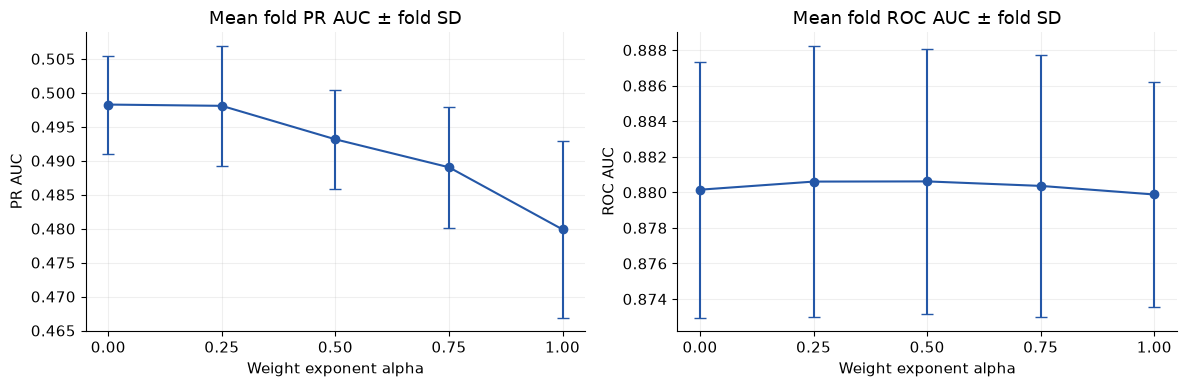

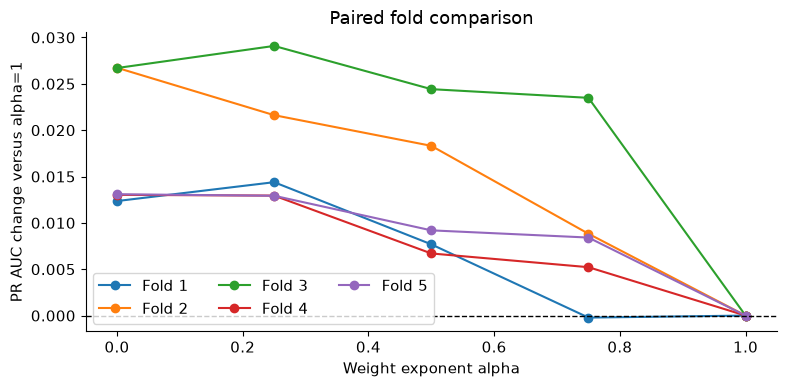

In [10]:
FIG_DIR = RUN_DIR/'figures'; FIG_DIR.mkdir(exist_ok=True)
ordered = leaderboard.sort_values('alpha')
names = ordered.candidate.tolist()
colors = dict(zip(names, ['#2457A7','#BD6C17','#647B36','#AE4D83','#52525B']))
def finish_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR/f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, metric in zip(axes,['PR_AUC','ROC_AUC']):
    ax.errorbar(ordered.alpha, ordered['mean_'+metric], yerr=ordered['sd_'+metric], fmt='o-', capsize=4, color='#2457A7')
    ax.set(xlabel='Weight exponent alpha', ylabel=metric.replace('_',' '), title='Mean fold '+metric.replace('_',' ')+' ± fold SD')
    ax.set_xticks(ordered.alpha); ax.grid(alpha=.2)
finish_figure(fig,'01_mean_fold_metrics')

reference = fold_metrics.loc[fold_metrics.alpha.eq(1),['fold','PR_AUC_trapezoidal']].rename(columns={'PR_AUC_trapezoidal':'reference'})
paired = fold_metrics.merge(reference,on='fold',validate='many_to_one')
paired['delta_PR_AUC'] = paired.PR_AUC_trapezoidal-paired.reference
paired.to_csv(RUN_DIR/'paired_fold_deltas.csv',index=False)
fig, ax = plt.subplots(figsize=(8,4))
for fold, block in paired.groupby('fold'):
    block=block.sort_values('alpha')
    ax.plot(block.alpha,block.delta_PR_AUC,marker='o',label=f'Fold {fold}')
ax.axhline(0,color='black',ls='--',lw=1)
ax.set(xlabel='Weight exponent alpha',ylabel='PR AUC change versus alpha=1',title='Paired fold comparison'); ax.legend(ncol=3)
finish_figure(fig,'02_paired_deltas')

## 10. Per-dataset PR AUC and ROC AUC
Compare candidates within each dataset. PR AUC depends on positive prevalence: dataset 2’s high positive fraction makes its PR AUC unsuitable for direct comparison with dataset 0’s. Counts and prevalence are in the table above.

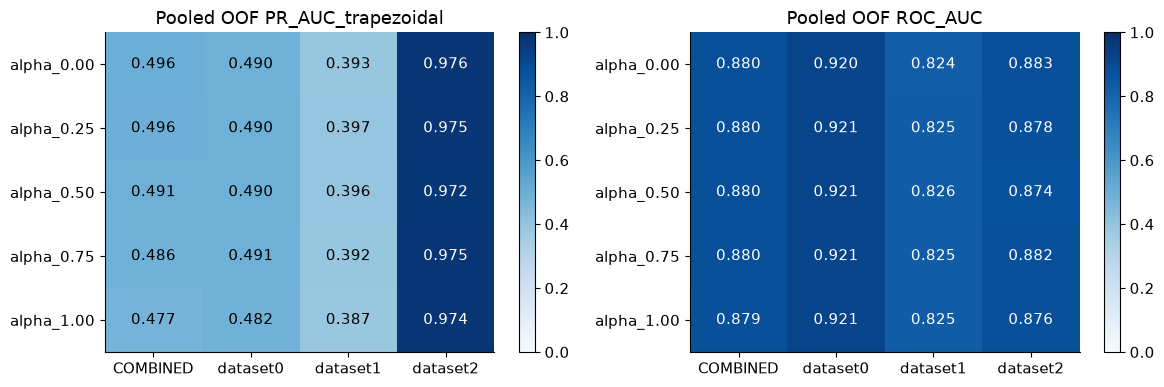

In [11]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, metric in zip(axes,['PR_AUC_trapezoidal','ROC_AUC']):
    matrix=dataset_metrics.pivot(index='candidate',columns='dataset_id',values=metric).reindex(names)
    im=ax.imshow(matrix.to_numpy(),vmin=0,vmax=1,cmap='Blues',aspect='auto')
    ax.set_xticks(range(len(matrix.columns)),matrix.columns)
    ax.set_yticks(range(len(names)),names); ax.set_title('Pooled OOF '+metric)
    for i in range(len(matrix)):
        for j in range(len(matrix.columns)):
            v=matrix.iloc[i,j]
            ax.text(j,i,f'{v:.3f}' if np.isfinite(v) else 'N/A',ha='center',va='center',color='white' if v>.65 else 'black')
    fig.colorbar(im,ax=ax)
finish_figure(fig,'03_dataset_metrics')

## 11. OOF PR and ROC curves
Each panel uses identical rows across candidates. The PR dashed line is positive prevalence; the ROC dashed line is chance ranking. These curves combine predictions from five fitted models per candidate.

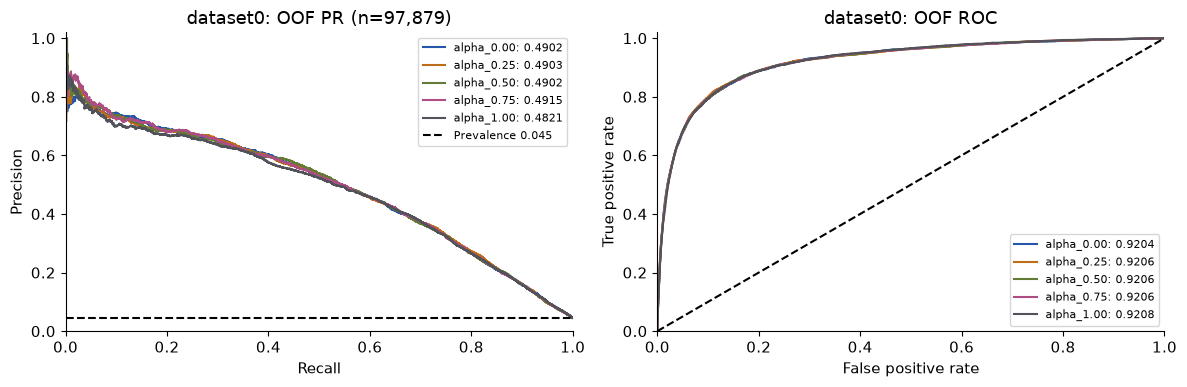

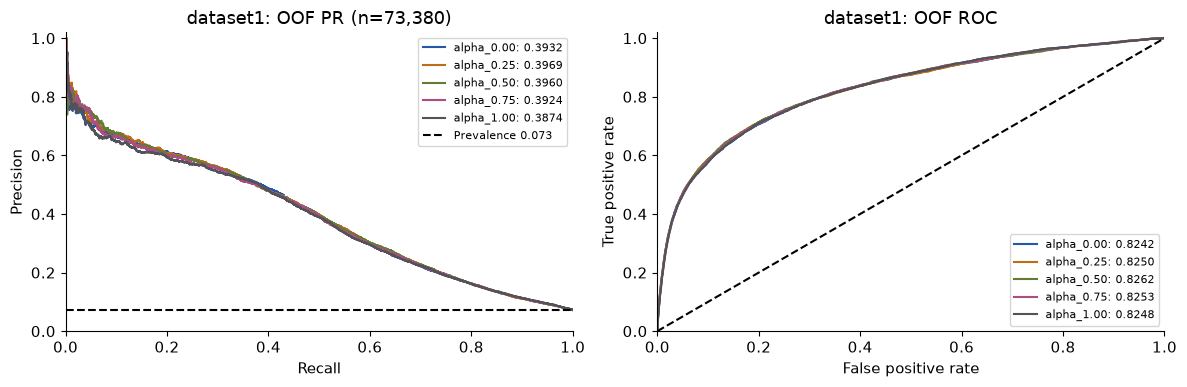

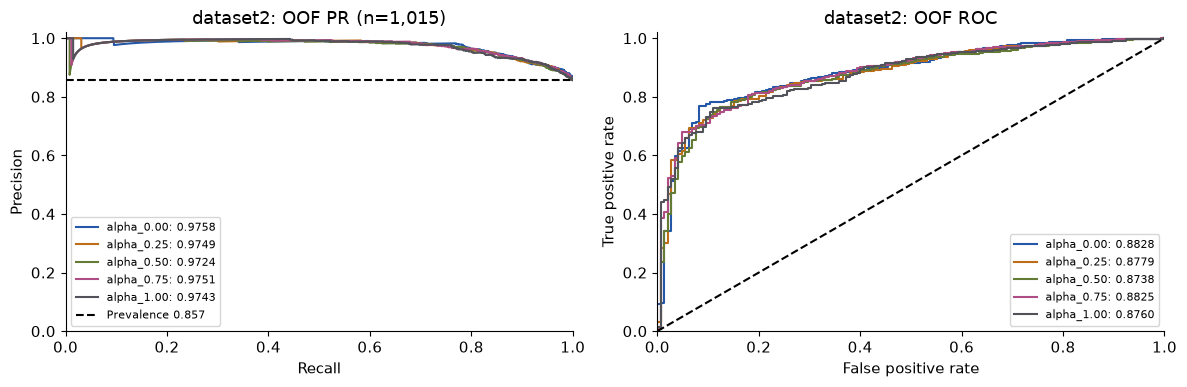

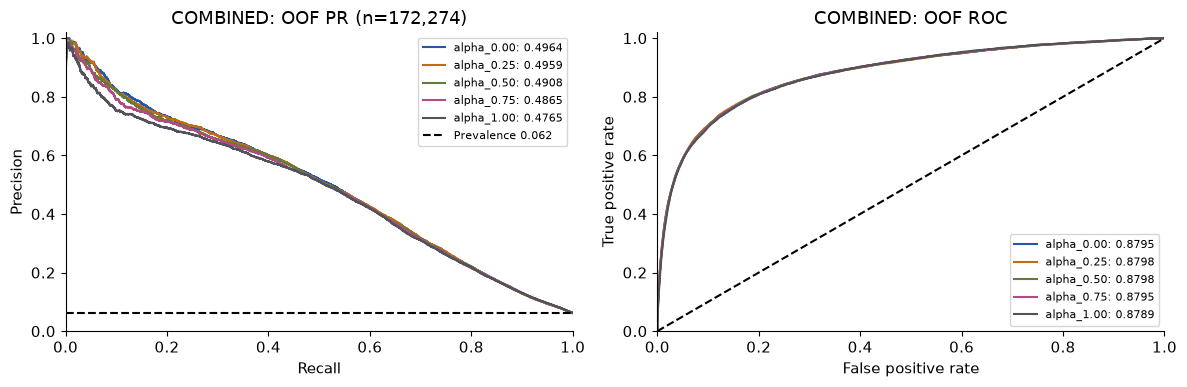

In [12]:
oof = {name: pd.read_csv(RUN_DIR/name/'oof_predictions.csv.gz', dtype={'transcript_id':str}) for name in names}
reference_frame=oof[names[0]]
for frame in oof.values():
    assert frame[['dataset_id']+KEY+['label','validation_fold']].equals(reference_frame[['dataset_id']+KEY+['label','validation_fold']])
for dataset in [*reference_frame.dataset_id.unique(),'COMBINED']:
    mask = np.ones(len(reference_frame),dtype=bool) if dataset=='COMBINED' else reference_frame.dataset_id.eq(dataset).to_numpy()
    y=reference_frame.loc[mask,'label'].to_numpy()
    if len(np.unique(y))<2:
        print(dataset,': skipped curves (fewer than two classes)'); continue
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    for name in names:
        p=oof[name].loc[mask,'score'].to_numpy()
        precision,recall,_=precision_recall_curve(y,p)
        fpr,tpr,_=roc_curve(y,p)
        axes[0].plot(recall,precision,color=colors[name],label=f'{name}: {auc(recall,precision):.4f}')
        axes[1].plot(fpr,tpr,color=colors[name],label=f'{name}: {roc_auc_score(y,p):.4f}')
    axes[0].axhline(y.mean(),color='black',ls='--',label=f'Prevalence {y.mean():.3f}')
    axes[1].plot([0,1],[0,1],'k--')
    axes[0].set(xlabel='Recall',ylabel='Precision',title=f'{dataset}: OOF PR (n={len(y):,})')
    axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title=f'{dataset}: OOF ROC')
    for ax in axes: ax.set_xlim(0,1); ax.set_ylim(0,1.02); ax.legend(fontsize=8)
    finish_figure(fig,f'04_curves_{dataset}')

## 12. Epoch diagnostics
Curves average validation results across folds at each epoch. They diagnose learning but do not change the fixed final-epoch selection in this round. Do not compare weighted training loss magnitudes across different weights.

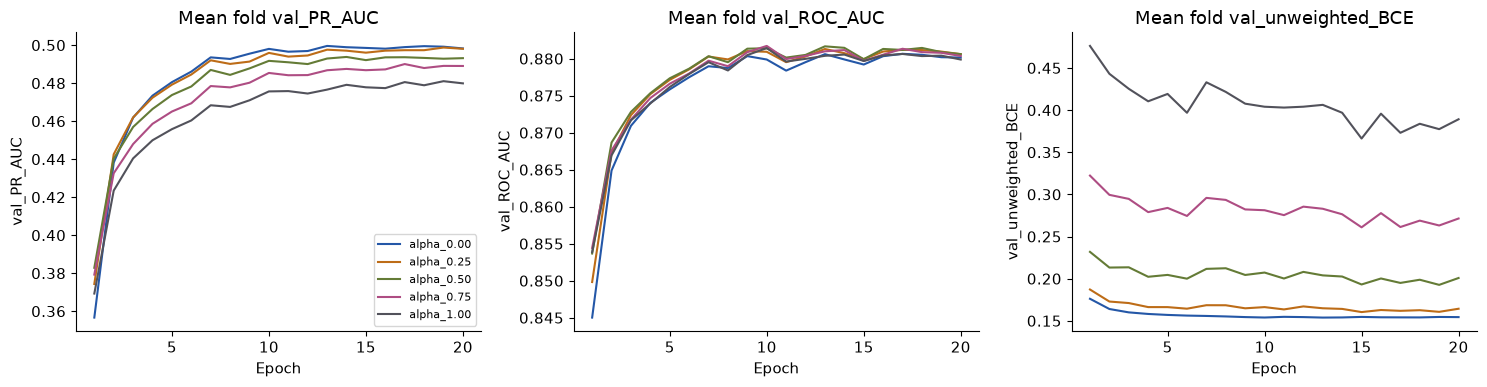

In [13]:
histories=[]
for name in names:
    for path in sorted((RUN_DIR/name).glob('fold_*_history.csv')):
        histories.append(pd.read_csv(path).assign(candidate=name,fold=int(path.name.split('_')[1])))
history=pd.concat(histories,ignore_index=True)
history.to_csv(RUN_DIR/'all_epoch_history.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for name in names:
    h=history.loc[history.candidate.eq(name)].groupby('epoch').mean(numeric_only=True)
    for ax,metric in zip(axes,['val_PR_AUC','val_ROC_AUC','val_unweighted_BCE']):
        ax.plot(h.index,h[metric],label=name,color=colors[name]); ax.set(xlabel='Epoch',ylabel=metric,title='Mean fold '+metric)
axes[0].legend(fontsize=8)
finish_figure(fig,'05_epoch_diagnostics')

## 13. Refit selected alpha on all TRAIN and save
Fit preprocessing and the selected model on TRAIN only, for the same 20 epochs. This step does not evaluate TRAIN or access TEST labels. Saved fold and final weights can be reused without retraining.


In [14]:
if RUN_TRAINING and REFIT_SELECTED:
    folder=RUN_DIR/'selected'; folder.mkdir(exist_ok=True)
    selected_config=dict(BASE_CONFIG,alpha=float(selected.alpha))
    prep=fit_preprocessing(train_df)
    seq,aux=transform(train_df,prep)
    start=time.perf_counter()
    model,history=fit_model(seq,aux,train_df.label.to_numpy(dtype=np.float32),selected_config,seed=SEED)
    history.to_csv(folder/'train_history.csv',index=False)
    torch.save(dict(state_dict={k:v.detach().cpu() for k,v in model.state_dict().items()},
                    config=selected_config,architecture='SiteGRU',position_columns=POSITION_COLUMNS,
                    threshold=THRESHOLD),folder/'model.pt')
    joblib.dump(prep,folder/'preprocessing.joblib')
    (folder/'config.json').write_text(json.dumps(selected_config,indent=2))
    (folder/'fit_summary.json').write_text(json.dumps(dict(train_sites=len(train_df),seconds=time.perf_counter()-start,
        parameters=sum(p.numel() for p in model.parameters())),indent=2))
    del model,seq,aux,prep
    gc.collect()
    print('Saved selected model:',folder)


Epoch 01/20: loss=0.2166
Epoch 05/20: loss=0.1559
Epoch 10/20: loss=0.1509
Epoch 15/20: loss=0.1486
Epoch 20/20: loss=0.1467
Saved selected model: /home/ubuntu/project/outputs/gru_class_weight_train_test/20261014T081820_206913Z/selected


## 14. Optional TEST-only evaluation — also works without retraining
Enable `EVALUATE_TEST` only after model selection is complete. Predictions cover retained cleaned TEST sites only; they are not a full raw-JSON submission. Cleaner counts are saved alongside metrics to show QC coverage. Threshold metrics use the checkpoint’s fixed threshold of 0.5; ROC AUC, trapezoidal PR AUC and AP use continuous scores.

To evaluate later: set `RUN_TRAINING=False`, `EXISTING_RUN_DIR` to the completed run, and `EVALUATE_TEST=True`, then Run All. The saved input paths must still exist. Only load your own trusted checkpoints and preprocessing files.


In [15]:
if EVALUATE_TEST:
    folder=RUN_DIR/'selected'
    if not (folder/'model.pt').is_file(): raise FileNotFoundError('Refit selected model first (REFIT_SELECTED=True)')
    checkpoint=torch.load(folder/'model.pt',map_location=DEVICE,weights_only=True)
    cfg=checkpoint['config']; THRESHOLD=float(checkpoint['threshold'])
    model=SiteGRU(cfg['hidden_size'],cfg['dropout']).to(DEVICE)
    model.load_state_dict(checkpoint['state_dict'])
    prep=joblib.load(folder/'preprocessing.joblib')
    test_frames={}; test_scores={}; coverage=[]
    prediction_dir=folder/'test_predictions'; prediction_dir.mkdir(exist_ok=True)
    for name,paths in input_paths.items():
        if sha256_file(paths['test_file']) != paths['test_sha256']: raise ValueError('TEST file changed since CV')
        frame=read_partition(Path(paths['test_file']),name,'test')
        seq,aux=transform(frame,prep)
        scores=predict_scores(model,seq,aux,PREDICT_BATCH_SIZE)
        test_frames[name]=frame; test_scores[name]=scores
        output=frame[['dataset_id']+KEY+['gene_id','group_id','label','split']].copy()
        output['score']=scores; output['prediction']=(scores>=THRESHOLD).astype(int)
        output.to_csv(prediction_dir/f'{name}_test_predictions.csv',index=False)
        meta=json.loads(Path(paths['manifest_file']).read_text())
        for row in meta.get('summaries',[]):
            if row['split']=='test': coverage.append(row)
    test_metrics=evaluate_tables(test_frames,test_scores,'selected','held_out_TEST')
    test_metrics.to_csv(folder/'test_metrics.csv',index=False)
    pd.DataFrame(coverage).to_csv(folder/'test_cleaning_coverage.csv',index=False)
    display(test_metrics.round(5))
    for name in [*test_frames,'COMBINED']:
        y=np.concatenate([f.label.to_numpy() for f in test_frames.values()]) if name=='COMBINED' else test_frames[name].label.to_numpy()
        p=np.concatenate(list(test_scores.values())) if name=='COMBINED' else test_scores[name]
        if len(np.unique(y))<2:
            print(name,': fewer than two classes; AUC curves unavailable'); continue
        precision,recall,_=precision_recall_curve(y,p); fpr,tpr,_=roc_curve(y,p)
        fig,axes=plt.subplots(1,2,figsize=(12,4))
        axes[0].plot(recall,precision,label=f'PR AUC={auc(recall,precision):.4f}')
        axes[0].axhline(y.mean(),color='gray',ls='--',label=f'Prevalence={y.mean():.3f}')
        axes[0].set(xlabel='Recall',ylabel='Precision',title=f'{name}: held-out TEST PR')
        axes[1].plot(fpr,tpr,label=f'ROC AUC={roc_auc_score(y,p):.4f}')
        axes[1].plot([0,1],[0,1],'k--'); axes[1].set(xlabel='False positive rate',ylabel='True positive rate',title=f'{name}: held-out TEST ROC')
        for ax in axes: ax.set_xlim(0,1); ax.set_ylim(0,1.02); ax.legend()
        finish_figure(fig,f'06_test_curves_{name}')
    del model,prep
else:
    print('TEST evaluation disabled. Finish tuning before enabling EVALUATE_TEST.')


TEST evaluation disabled. Finish tuning before enabling EVALUATE_TEST.


## Interpretation and validation
- Compare class weights using TRAIN OOF results only. Mean fold AUC and pooled OOF AUC are different quantities. Fold SD is not a confidence interval.
- Preserve the same folds when moving to architecture experiments or building an OOF ensemble. Do not compare these CV numbers directly with older all-data-fit results.
- Dataset2 grouping is assumed; review the split audit and do not claim biological independence that these identifiers cannot establish.
- Class-weighted sigmoid outputs are scores, not guaranteed calibrated probabilities.
- Outputs include input hashes, split audits, fold assignments, fold models/scalers, OOF scores, metrics, histories, comparison plots and the selected TRAIN-fitted model. Optional TEST evaluation adds per-dataset predictions, per-dataset/combined metrics and curves.
- Raw JSON submission export is intentionally separate: this notebook makes no fallback predictions for QC-rejected sites.

**Authoring validation:** Python cell syntax and synthetic input/preprocessing checks and dataset-specific split-policy regression checks were performed. Real data and PyTorch were unavailable in the authoring environment, so full training and plot execution were not verified here. To validate in your Ronin environment, select your `m6a-gru` kernel, set the cleaning run path, Restart Kernel → Run All, and inspect the split audits and generated charts. No synthetic scores are included as model results.
